# Assignment #3 - Academic Environment Representation

### Problem statement
Consider a university that needs a knowledge representation system to describe its academic environment. The system must represent students, professors, courses, departments, and research projects.

The following information is known:

- Every person has a name, an identification number, and an email address.
- A student is a person who has a student number and enrolls in courses.
- A professor is a person who has an academic rank and teaches courses.
- Every course has a course code, title, and credit hours.
- Each course belongs to a department.
- A professor may supervise several research projects.
- A research project has a title, a principal investigator, and one or more participating researchers.
- A postgraduate student may participate in a research project under a professor's supervision.

Your task is to develop an object-oriented representation of this domain and explain how the representation captures the relevant knowledge.

________________

### Utility Function for Drawing UML Class Diagrams


In [ ]:
%pip install mermaid-python

In [53]:
# declare drawing uml class diagrams utility function
import base64
import urllib.request
from IPython.display import Image, display

def draw_class_diagram_v2(mermaid_objects):
    encoded = base64.urlsafe_b64encode(mermaid_objects.encode("utf-8")).decode(
        "utf-8"
    )
    url = f"https://mermaid.ink/img/{encoded}"

    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as response:
        img_bytes = response.read()

    display(Image(data=img_bytes))

In [66]:
from mermaid import Mermaid

# 1. Define your dynamic color variable
custom_bg = "#888"  # Can be changed to any hex code

def draw_class_diagram(mermaid_objects):
# 2. Inject it into the f-string (note the doubled curly braces)
    mermaid_code = f"""
    %%{{init: {{ 'theme': 'neutral', 'themeVariables': {{ 'background': '{custom_bg}' }} }} }}%%
    {mermaid_objects}
    """
    return Mermaid(mermaid_code)

### Task 1: Identify classes and instances
Identify at least six classes required to represent the domain. For each class, provide two possible instances.

<pre>
    1- Person
        - person_lina(id -> 99999102, name -> Lina, email -> lina@university.edu)
        - Person_samir(id -> 99999301, name -> Samir, email -> samir@university.edu)

    2- Student is_a Person
        - student_lina(student_number -> 102)
        - student_salem(student_number -> 202)

    3- Postgraduate_Student is_a Student
        - postgraduate_student_lina()
        - postgraduate_student_salem()

    4- Professor is Person
        - professor_Samir(academic_rank -> "professor")
        - professor_khalid(academic_rank -> "Associate professor")

    5- Course
        - course_knowledge_representation(code -> 491112, credit_hours -> 3, title -> "Knowledge Representation")
        - course_big_data_analytics(code -> 489124, credit_hours -> 3, title -> "Big Data Analytics")

    6- Department
        - department_5211(code -> 5211, name -> "Artificial Intelligence"): 
        - department_8320(code -> 8320, name -> "Cybersecurity") 

    7- Research_Project
        - research_01(title -> "Medical Ontology Development")
        - research_02(title -> "Measuring Similarity Between Research Papers with Spark RDDs")
</pre>

____________________

### Task 2: Define attributes and relationships 

For each class, specify its attributes and identify its relationships with other classes.<br>
Distinguish between attributes that describe an object and relationships that connect it to other objects.<br>
#### Attributes whose names end with __rel represent relationships between objects, while all other attributes describe object properties.

#### - <b>Entity Frames</b>

<pre>
(Person
    <:id Integer>
    <:name String>
    <:email String>)
</pre>

<pre>
(Student
    <<b>:IS-A</b> Person>
    <:student_number Integer>)
</pre>

<pre>
(Postgraduate_Student
    <<b>:IS-A</b> Student>)
</pre>

<pre>
(Professor
    <<b>:IS-A</b> Person>
    <:academic_rank Integer>)
</pre>

<pre>
(Course
    <:code String>
    <:title String>
    <:credit_hours Integer>
    <:department__rel Department>
    <:teacher__rel Professor>)
</pre>

<pre>
(Department
    <:id Integer>
    <:name String>)
</pre>

<pre>
(Research_Project
    <:title String>
    <:investigator__rel Professor>)
</pre>


#### - <b>Relationship Frames</b>
<pre>
(Course_Enrollment
    <:course__rel Course>
    <:student__rel Student>)
</pre>

<pre>
(Research_Participation
    <:project__rel Research_Project>
    <:participant__rel Postgraduate_Student>)
</pre>

___________________

## Task 3: Represent inheritance

Develop an inheritance hierarchy that includes Person, Student, and Professor.

In [67]:
draw_class_diagram("""
classDiagram
    class Person {
        +id: Integer
        +name: String 
        +email: String
    }
    class Professor {
        +academic_rank: Integer
    }
    class Student {
        +student_number = Integer
    }
    class Postgraduate_Student {
    }
    
    %% Inheritance (IS-A)
    Person <|-- Student
    Student <|-- Postgraduate_Student
    Person <|-- Professor
""")

### Explanation:

* **Which attributes are inherited by subclasses?**
  * `id`, `name`, and `email` are defined once in `Person` and are automatically inherited by both `Student` and `Professor` subclasses.
  * `Postgraduate_Student` automatically inherit `student_number` from `Student` as well as `id`, `name`, and `email` from `Person`.

* **Why Student and Professor should be modeled as subclasses of Person:**
  * Both students and professors are human entities that share identical core properties (`id`, `name`, `email`). Modeling them as subclasses avoids code duplication, ensures consistent data-types across the application.

* **Whether a person could be both a student and a professor, and how your model would handle that situation:**<br>
    **No**, under the current design, a person cannot be both a student and a professor.

    * **Why:** `Student` and `Professor` are modeled as parallel, disjoint subclasses of `Person`. In standard object-oriented modeling, an object can only be instantiated as a single leaf class in the hierarchy.
    * **Suggested Solution (Role Composition):** Decouple identity from actions by creating an abstract `Role` class with `StudentRole` and `ProfessorRole` as subclasses. Connect `Person` to `Role` via a 1-to-many composition relationship (`Person` $\rightarrow$ `* Role`), allowing a single `Person` instance to hold both `StudentRole` and `ProfessorRole` objects simultaneously.

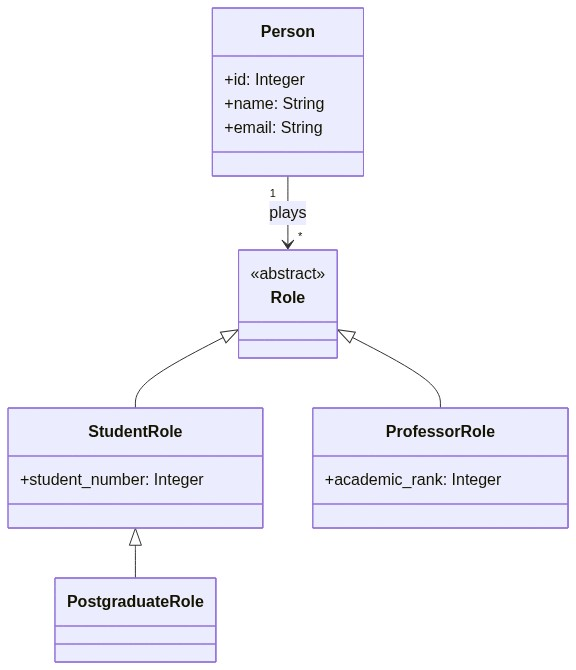

In [56]:
draw_class_diagram("""
classDiagram
    class Person {
        +id: Integer
        +name: String 
        +email: String
    }
    class Role {
        <<abstract>>
    }
    class StudentRole {
        +student_number: Integer
    }
    class ProfessorRole {
        +academic_rank: Integer
    }
    class PostgraduateRole {
    }

    Person "1" --> "*" Role : plays
    Role <|-- StudentRole
    Role <|-- ProfessorRole
    StudentRole <|-- PostgraduateRole""")

______________

# Task 4: Object representation

Represent the following individuals as objects using a notation of your choice, such as UML class diagrams, tables, or structured pseudocode.

<pre>
Student: Lina, student number S102, email lina@university.edu.
Professor: Dr. Samir, associate professor, email samir@university.edu.
Course: KR501, Knowledge Representation, 3 credit hours.
Research project: Medical Ontology Development, supervised by Dr. Samir, with Lina as a participating researcher.
</pre>

Show how the objects are connected and ensure that the representation is consistent with your class definitions.

#### 1. Core Entities (Instances)

```json
(student_Lina
    <:INSTANCE-OF Postgraduate_Student>
    <:id 99999102>
    <:name "Lina">
    <:email "lina@university.edu">
    <:student_number "S102">
)


(professor_Samir
    <:INSTANCE-OF Professor>
    <:id 99999301>
    <:name "Dr. Samir">
    <:email "samir@university.edu">
    <:academic_rank "Associate Professor">
)

(course_KR501
    <:INSTANCE-OF Course>
    <:code "KR501">
    <:title "Knowledge Representation">
    <:credit_hours 3>
    <:department__rel Department_CS_AI>
    <:teacher__rel professor_Samir>
)

(research_oroject_medical_ontology
    <:title "Medical Ontology Development">
    <:investigator__rel Professor_Samir>
)
```

#### 2. Relations (Instances)

```json
// Lina's participation in Dr. Samir's project
(Research_Participation_Lina
    <:project__rel Research_Project_Medical_Ontology>
    <:participant__rel Postgraduate_Student_Lina> // Where Postgraduate_Student_Lina IS-A Student_Lina
)
```

In [68]:
from mermaid import Mermaid

Mermaid("""
%%{init: {'theme': 'neutral', 'themeVariables': {
    'background': '#ffffff',
  }|}%%
classDiagram
    class Person {
        +Integer id
        +String name
        +String email
    }
    class Student {
        +Integer student_number
    }
    class Postgraduate_Student {
    }
    class Professor {
        +Integer academic_rank
    }
    class Course {
        +String code
        +String title
        +Integer credit_hours
    }
    class Department {
        +Integer id
        +String name
    }
    class Research_Project {
        +String title
    }
    class Course_Enrollment {
    }
    class Research_Participation {
    }

    %% Inheritance (IS-A)
    Person <|-- Student
    Student <|-- Postgraduate_Student
    Person <|-- Professor

    %% Relationships (__rel)
    Course --> Department : department
    Course --> Professor : teacher
    Research_Project --> Professor : investigator
    Course_Enrollment --> Course : course
    Course_Enrollment --> Student : student
    Research_Participation --> Research_Project : project
    Research_Participation --> Postgraduate_Student : participant""")


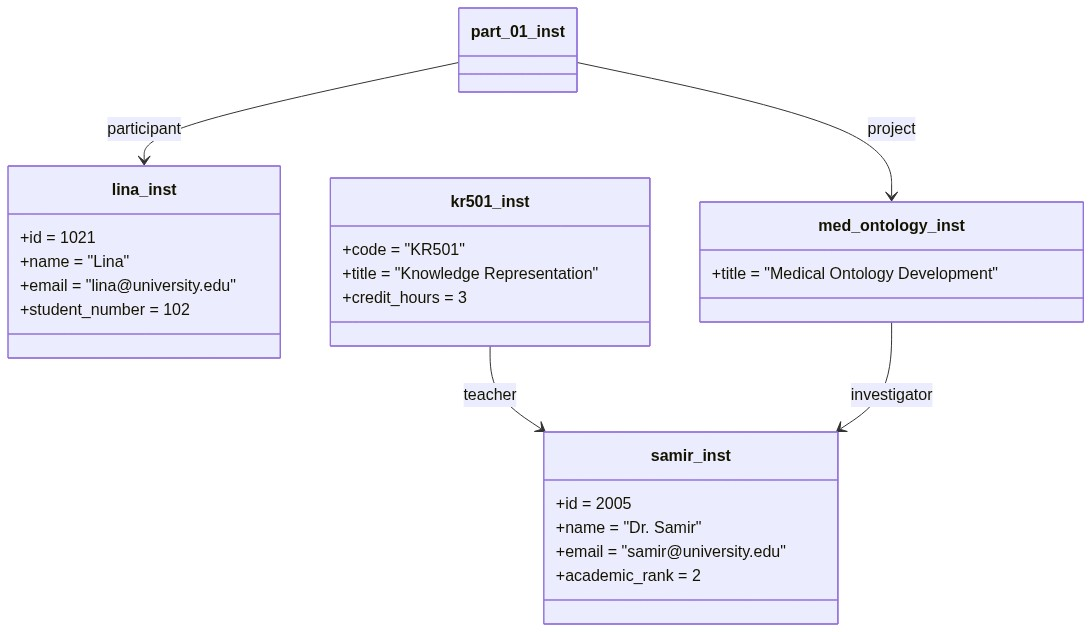

In [51]:
import base64
import urllib.request
from IPython.display import Image, display

mermaid_objects = """
classDiagram
    class lina_inst {
        +id = 1021
        +name = "Lina"
        +email = "lina@university.edu"
        +student_number = 102
    }
    class samir_inst {
        +id = 2005
        +name = "Dr. Samir"
        +email = "samir@university.edu"
        +academic_rank = 2
    }
    class kr501_inst {
        +code = "KR501"
        +title = "Knowledge Representation"
        +credit_hours = 3
    }
    class med_ontology_inst {
        +title = "Medical Ontology Development"
    }
    class part_01_inst {
    }

    %% Object Links matching Frame __rel definitions
    kr501_inst --> samir_inst : teacher
    med_ontology_inst --> samir_inst : investigator
    part_01_inst --> med_ontology_inst : project
    part_01_inst --> lina_inst : participant
"""

encoded = base64.urlsafe_b64encode(mermaid_objects.encode("utf-8")).decode(
    "utf-8"
)
url = f"https://mermaid.ink/img/{encoded}"

req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req) as response:
  img_bytes = response.read()

display(Image(data=img_bytes))


### Inheritance Hierarchy

```text
                  ┌──────────────────────────────┐
                  │            Person            │
                  ├──────────────────────────────┤
                  │  • id: Integer               │
                  │  • name: String              │
                  │  • email: String             │
                  └──────────────┬───────────────┘
                                 ▲
                                 │
                  ┌──────────────┴──────────────┐
                  │                             │
        ┌─────────┴──────────┐        ┌─────────┴──────────┐
        │      Student       │        │     Professor      │
        ├────────────────────┤        ├────────────────────┤
        │  • student_number  │        │  • academic_rank   │
        └────────────────────┘        └────────────────────┘
```